# Alpha Chaser: concentrated equity momentum (research)

Monthly-rebalanced strategy that rotates into the strongest high-beta US equity segments.

1. **Eligibility**: month-end price above the 100-day SMA and positive 3-month return.
2. **Selection**: the 2 eligible ETFs with the highest 3-month momentum, equally weighted (50% each). Current holdings receive a +10 pp momentum bonus (hysteresis) to limit turnover.
3. **Risk-off**: one eligible ETF means 50% in it and 50% in T-bills; none means 100% T-bills (SHV).

The second half of the notebook tests whether the excess return is alpha, and how much of it comes from having picked the universe with hindsight.

In [1]:
import os
import sys

import numpy as np
import pandas as pd

sys.path.append(os.path.join("..", "src"))
from data import download_prices, prepare_monthly
from strategies import trend_momentum_signal, alpha_chaser_weights
from backtest import run_backtest, allocation_stats, stress_test, subperiod_table
import benchmarks as bm

np.random.seed(42)
DATA_DIR = os.path.join("..", "data")

/opt/miniconda3/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
UNIVERSE = ["SPY", "QQQ", "SMH", "XLK", "XLY", "IWM", "ARKK", "SHV"]
SMA_WINDOW = 100
TOP_N = 2
MOMENTUM_BUFFER = 0.10
MAX_WEIGHT = 0.50          # weight of a single eligible ETF; the rest goes to T-bills

TICKER_COSTS = {"SPY": 0.0002, "QQQ": 0.0003, "XLK": 0.0003, "XLY": 0.0003, "SMH": 0.0005,
                "IWM": 0.0004, "ARKK": 0.0008, "SHV": 0.0001}

## 1. Data and signal

In [3]:
prices = download_prices(UNIVERSE, years=20, cache_path=os.path.join(DATA_DIR, "prices_alpha.csv"))
md = prepare_monthly(prices, SMA_WINDOW)
signal = trend_momentum_signal(md)

print(f"\n{len(md.prices)} months x {md.prices.shape[1]} ETFs. Latest eligibility:")
print(signal.tail(3).T)

Downloaded 2006-10-17 -> 2026-10-12. First valid date per ETF:
  SPY   2006-10-17
  QQQ   2006-10-17
  SMH   2006-10-17
  XLK   2006-10-17
  XLY   2006-10-17
  IWM   2006-10-17
  ARKK  2014-10-31
  SHV   2007-01-11

240 months x 8 ETFs. Latest eligibility:
Date    2026-07-31  2026-08-31  2026-09-30
Ticker                                    
ARKK         False        True        True
IWM           True        True       False
QQQ           True       False        True
SHV           True        True        True
SMH           True       False       False
SPY           True        True        True
XLK           True       False        True
XLY          False       False       False


## 2. Portfolio construction

In [4]:
weights = alpha_chaser_weights(signal, md.mom_3m, TOP_N, MOMENTUM_BUFFER, MAX_WEIGHT)

print("Latest portfolio:")
print((weights.iloc[-1][weights.iloc[-1] > 0] * 100).round(1).to_string())

Latest portfolio:
Ticker
ARKK    50.0
SPY     50.0


## 3. Backtest net of costs

PERFORMANCE: Alpha Chaser  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)     17.51%     18.03%   0.86  -21.3%
Net (per-ETF costs)  17.32%     18.02%   0.85  -21.5%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 



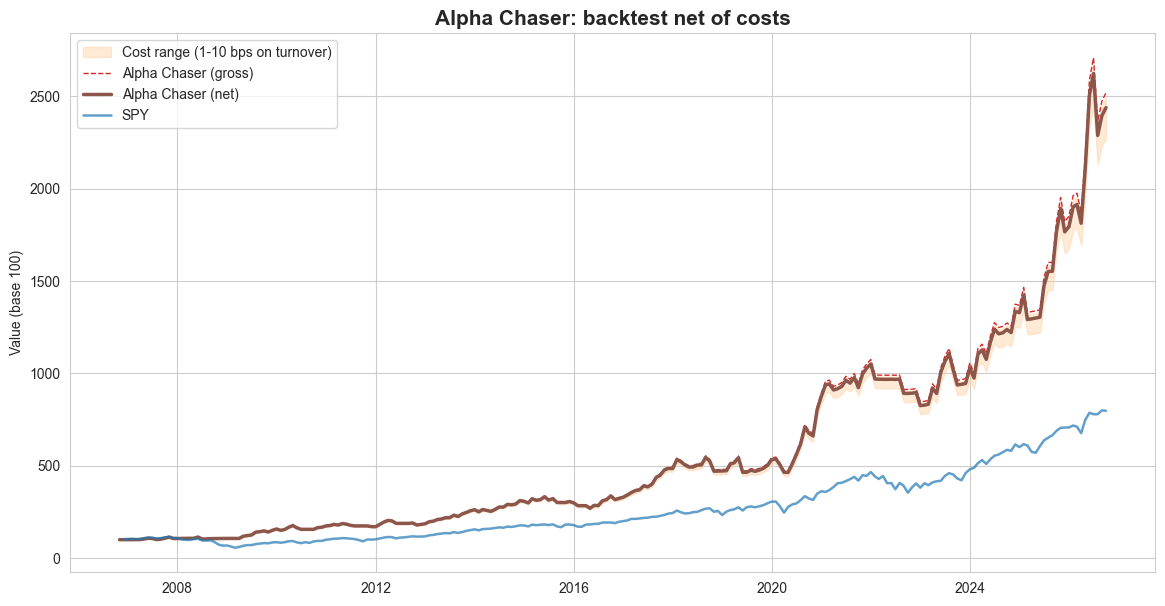

ALLOCATION HISTORY: 240 months since 2006-10-31
        Months held  Frequency %  Avg weight when held %  Max weight %
Ticker                                                                
SMH             105         43.8                    50.0          50.0
QQQ              62         25.8                    50.0          50.0
SHV              57         23.8                    94.7         100.0
ARKK             55         22.9                    50.0          50.0
XLK              54         22.5                    50.0          50.0
XLY              43         17.9                    50.0          50.0
IWM              37         15.4                    50.0          50.0
SPY              16          6.7                    50.0          50.0 



In [5]:
bt = run_backtest(weights, md.returns, TICKER_COSTS, "Alpha Chaser",
                  colors=("#d62728", "#8c564b", "#ffcc99"))
alloc = allocation_stats(weights, os.path.join(DATA_DIR, "allocation_alpha.csv"))

## 4. Stress test and sub-periods

STRESS TEST: Alpha Chaser
Scenario                         |  Impact on average portfolio
2008 systemic crash              |                      -37.33%
2022 tech/inflation shock        |                      -28.73%
Dot-com bust                     |                      -41.07%


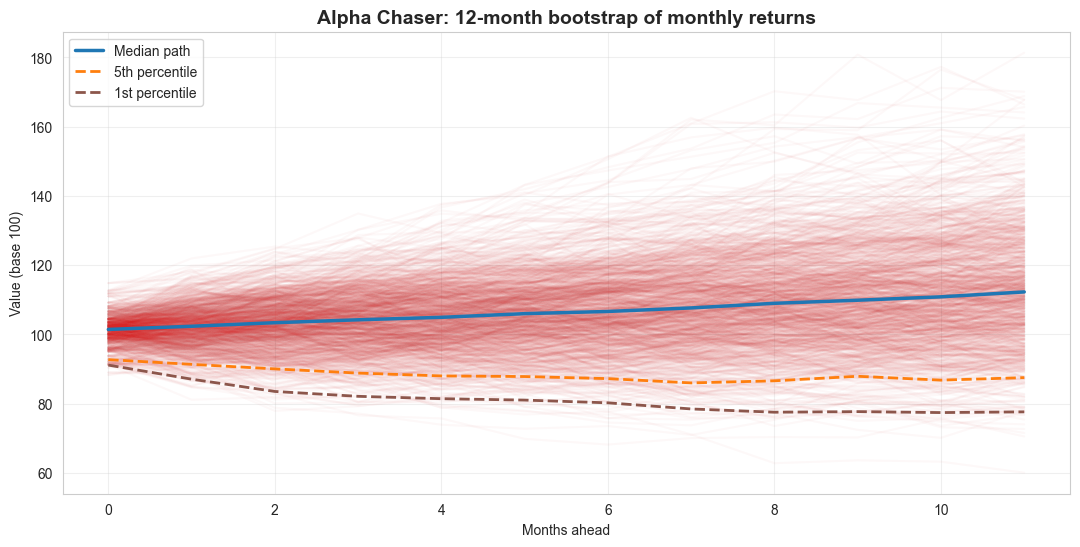

12-month VaR 95%: 12.47%   |   12-month VaR 99%: 22.36%

SUB-PERIODS (gross of costs)
  Period Strategy CAGR SPY CAGR Excess CAGR Sharpe Max DD
Last 10Y        21.93%   15.10%       6.83%   0.93 -21.3%
 Last 5Y        21.32%   12.40%       8.92%   0.85 -21.3%
 Last 3Y        36.65%   20.17%      16.48%   1.44 -12.8% 



In [6]:
SCENARIOS = {
    "2008 systemic crash":       {"SPY": -0.40, "QQQ": -0.45, "XLK": -0.45, "XLY": -0.45, "SMH": -0.50,
                                  "IWM": -0.50, "ARKK": -0.55, "SHV": 0.0},
    "2022 tech/inflation shock": {"SPY": -0.20, "QQQ": -0.35, "XLK": -0.30, "XLY": -0.35, "SMH": -0.35,
                                  "IWM": -0.25, "ARKK": -0.65, "SHV": 0.0},
    "Dot-com bust":              {"SPY": -0.25, "QQQ": -0.60, "XLK": -0.65, "XLY": -0.30, "SMH": -0.60,
                                  "IWM": -0.10, "ARKK": -0.75, "SHV": 0.0},
}
stress_test(weights, md.returns, "Alpha Chaser", SCENARIOS, unmapped_shock=-0.10)
subperiod_table(weights, md.returns, years=(10, 5, 3));

## 5. Alpha and benchmark analysis

- **SPY**: the market. **QQQ**: the closest passive alternative (high-beta growth).
- **1/N**: same universe, no signal. Measures the value of picking 2 ETFs.
- **Trend 1/N**: textbook trend-following on the same universe. Measures the value of the engine.
- **Factor models**: CAPM, Fama-French 5, then FF5 + momentum (UMD). If alpha disappears with UMD, it is just the momentum premium.

Weights check: every month sums to 100%.

Fama-French: 1963-07 -> 2026-08, downloaded
Common sample: 2007-08 -> 2026-08 (229 months)

BENCHMARK COMPARISON: Alpha Chaser (net)
                       CAGR     Vol Sharpe    MaxDD Calmar Active      TE    IR  Beta  Alpha  t(α) p(ΔSR)
Alpha Chaser (net)   18.06%  18.35%   0.92  -21.45%   0.84                                               
S&P 500 (SPY)        11.11%  15.55%   0.67  -50.78%   0.22  6.56%  15.78%  0.42  0.68  9.87%  2.97   0.23
Nasdaq 100 (QQQ)     16.21%  18.97%   0.82  -49.74%   0.33  1.44%  15.33%  0.09  0.64  7.00%  2.12   0.58
1/N universe         14.28%  19.69%   0.71  -50.54%   0.28  3.00%  15.05%  0.20  0.64  7.99%  2.69   0.24
Trend 1/N (10m SMA)  11.01%  12.96%   0.76  -18.76%   0.59  7.03%   9.20%  0.76  1.25  4.57%  2.23   0.16
Active = strategy - benchmark (ann.) | TE = tracking error | IR = Active / TE | Alpha, Beta from regressing strategy excess returns on benchmark excess returns (Newey-West t)
p(ΔSR) = p-val

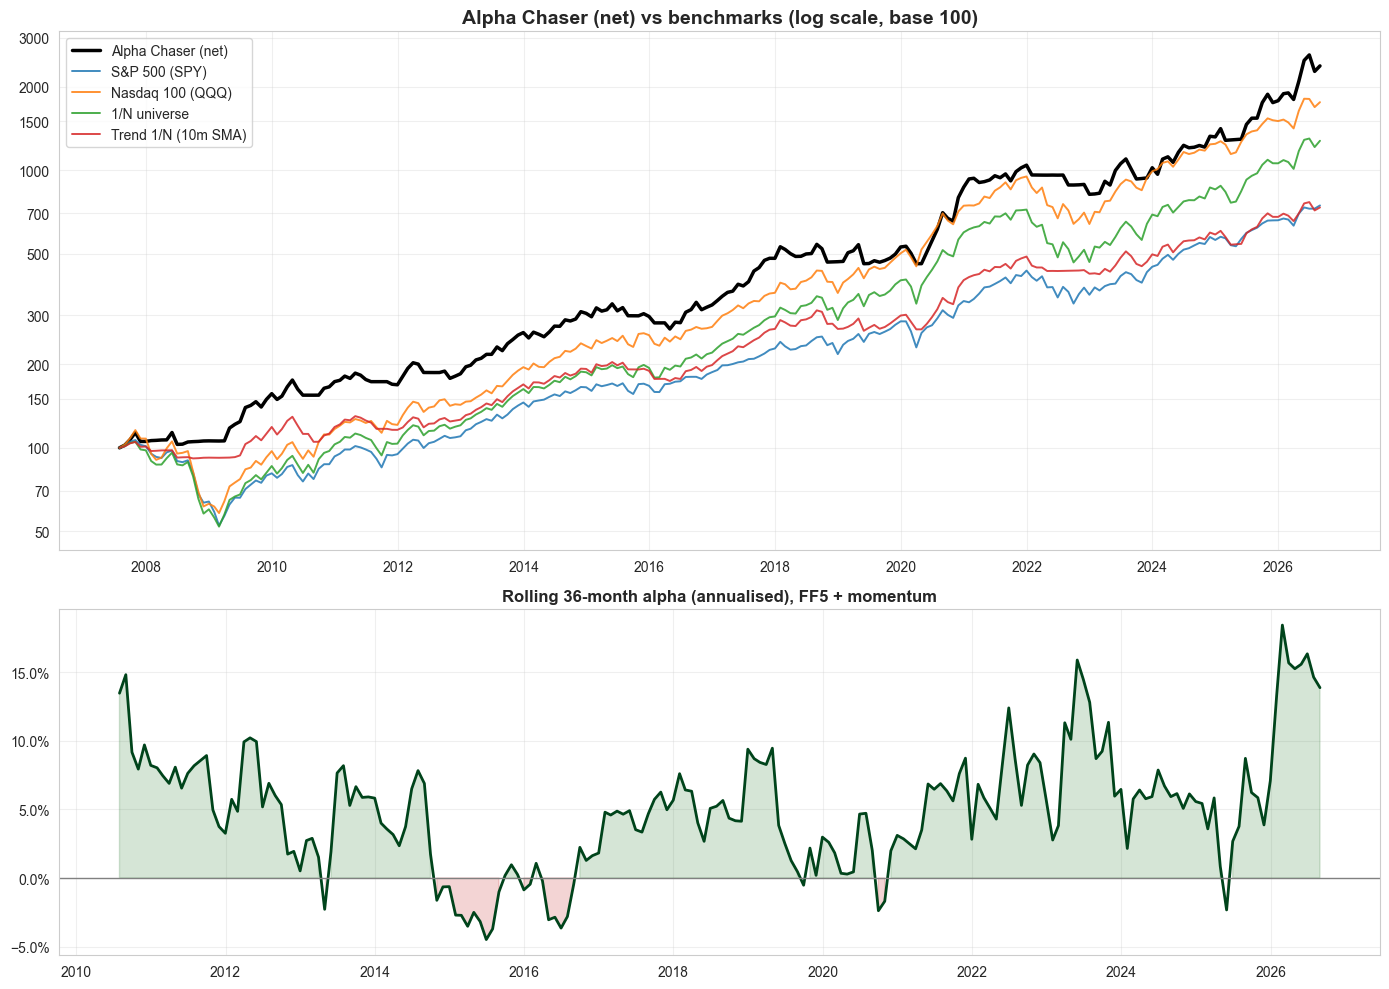

In [7]:
STRAT_NAME = "Alpha Chaser (net)"
STRAT, WEIGHTS, R = bt["net"].copy(), weights, md.returns
RISKY = [c for c in md.prices.columns if c != "SHV"]

bm.check_weights(WEIGHTS)
ff = bm.load_fama_french(os.path.join(DATA_DIR, "ff_factors_monthly.csv"))
rf = ff["RF"] if ff is not None else R["SHV"].fillna(0.0)

benchmarks = {
    "S&P 500 (SPY)":       R["SPY"],
    "Nasdaq 100 (QQQ)":    R["QQQ"],
    "1/N universe":        bm.returns_from_weights(bm.equal_weight(md.prices, RISKY), R),
    "Trend 1/N (10m SMA)": bm.returns_from_weights(bm.naive_trend(md.prices, RISKY), R),
}
S, B, RF = bm.align_sample(STRAT, benchmarks, rf, WEIGHTS)
comparison = bm.benchmark_comparison(S, B, RF, STRAT_NAME)

FF5 = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
if ff is not None:
    F = ff.reindex(S.index)
    bm.factor_regression(S, F[["Mkt-RF"]], RF, "CAPM")
    bm.factor_regression(S, F[FF5], RF, "Fama-French 5")
    bm.factor_regression(S, F[FF5 + ["UMD"]], RF, "Fama-French 5 + momentum")
    common = F.dropna().index
    bm.plot_alpha(S.loc[common], {k: v.loc[common] for k, v in B.items()}, STRAT_NAME,
                  bm.rolling_alpha(S, F[FF5 + ["UMD"]], RF), "FF5 + momentum")
else:
    bm.plot_alpha(S, B, STRAT_NAME, bm.rolling_alpha(S, (B["S&P 500 (SPY)"] - RF).to_frame("MKT"), RF), "CAPM vs SPY")

## 6. Robustness: universe-selection bias (work in progress)

The original universe (semiconductors, tech, ARKK...) was chosen knowing that these segments led the last decade. To separate the engine from the hindsight, the same engine, parameters and costs are run on a broad universe that adds all remaining S&P 500 sectors, including the laggards.

Next steps: parameter sensitivity (SMA window, buffer, top-N) on an out-of-sample split, and handling of sectors with late inception dates (XLRE 2015, XLC 2018).

In [8]:
EXTRA_SECTORS = ["XLE", "XLF", "XLV", "XLI", "XLP", "XLU", "XLB", "XLRE", "XLC"]
UNIVERSE_BROAD = [t for t in UNIVERSE if t != "SHV"] + EXTRA_SECTORS
COSTS_BROAD = {**TICKER_COSTS, **{t: 0.0003 for t in EXTRA_SECTORS}, "XLRE": 0.0004, "XLC": 0.0004}

prices_b = download_prices(UNIVERSE_BROAD + ["SHV"], years=20, verbose=False,
                           cache_path=os.path.join(DATA_DIR, "prices_alpha_broad.csv"))
print("First valid date of the added sectors:")
for t in EXTRA_SECTORS:
    print(f"  {t:<5} {prices_b[t].first_valid_index():%Y-%m-%d}")

md_b = prepare_monthly(prices_b, SMA_WINDOW)
w_b = alpha_chaser_weights(trend_momentum_signal(md_b), md_b.mom_3m, TOP_N, MOMENTUM_BUFFER, MAX_WEIGHT)
bt_b = run_backtest(w_b, md_b.returns, COSTS_BROAD, f"Alpha Chaser, broad universe ({len(UNIVERSE_BROAD)})",
                    plot=False)
bm.check_weights(w_b)

name_b = f"Alpha Chaser BROAD ({len(UNIVERSE_BROAD)})"
rf_b = ff["RF"] if ff is not None else md_b.returns["SHV"].fillna(0.0)
bench_b = {
    "Alpha Chaser ORIGINAL (7)": bt["net"],
    "S&P 500 (SPY)":             md_b.returns["SPY"],
    "Nasdaq 100 (QQQ)":          md_b.returns["QQQ"],
    "1/N broad universe":        bm.returns_from_weights(bm.equal_weight(md_b.prices, UNIVERSE_BROAD), md_b.returns),
    "Trend 1/N broad (10m SMA)": bm.returns_from_weights(bm.naive_trend(md_b.prices, UNIVERSE_BROAD), md_b.returns),
}
S_b, B_b, RF_b = bm.align_sample(bt_b["net"], bench_b, rf_b, w_b)
comparison_b = bm.benchmark_comparison(S_b, B_b, RF_b, name_b)

First valid date of the added sectors:
  XLE   2006-10-17
  XLF   2006-10-17
  XLV   2006-10-17
  XLI   2006-10-17
  XLP   2006-10-17
  XLU   2006-10-17
  XLB   2006-10-17
  XLRE  2015-10-08
  XLC   2018-06-19
PERFORMANCE: Alpha Chaser, broad universe (16)  (2006-10 -> 2026-09, Sharpe uses rf = 2%)
                       CAGR Volatility Sharpe  Max DD
Gross (no costs)     12.52%     17.17%   0.61  -20.4%
Net (per-ETF costs)  12.27%     17.18%   0.60  -20.5%
Benchmark (SPY)      10.94%     15.31%   0.58  -50.8% 

Weights check: every month sums to 100%.

Common sample: 2007-08 -> 2026-08 (229 months)

BENCHMARK COMPARISON: Alpha Chaser BROAD (16)
                             CAGR     Vol Sharpe    MaxDD Calmar  Active      TE     IR  Beta   Alpha   t(α) p(ΔSR)
Alpha Chaser BROAD (16)    12.67%  17.54%   0.69  -20.50%   0.62                                                   
Alpha Chaser ORIGINAL (7)  18.06%  18.35%   0.92  -21.45%   0.84  -4.85%  11.22%  -0.43  0.77  -0.98%  -0.48   0.1

FACTOR MODEL: FF5 + UMD, original universe
         Coefficient t-stat (NW) p-value
Alpha   +10.86% p.a.        3.32   0.001
Mkt-RF        +0.652        6.07   0.000
SMB           +0.114        0.79   0.430
HML           -0.211       -1.54   0.124
RMW           -0.357       -1.63   0.103
CMA           -0.163       -0.78   0.435
UMD           +0.077        0.92   0.358
R² = 0.42 | 229 months | Newey-West lags = 4
Alpha +10.86% p.a., significant at 1%

FACTOR MODEL: FF5 + UMD, broad universe
        Coefficient t-stat (NW) p-value
Alpha   +5.74% p.a.        1.81   0.070
Mkt-RF       +0.666        7.67   0.000
SMB          +0.113        0.77   0.444
HML          -0.115       -0.76   0.449
RMW          -0.309       -1.93   0.054
CMA          -0.006       -0.02   0.981
UMD          +0.113        1.17   0.243
R² = 0.42 | 229 months | Newey-West lags = 4
Alpha +5.74% p.a., significant at 10%

HOLDINGS FREQUENCY, BROAD UNIVERSE
        Months held  Frequency % Added sector
Ticker              

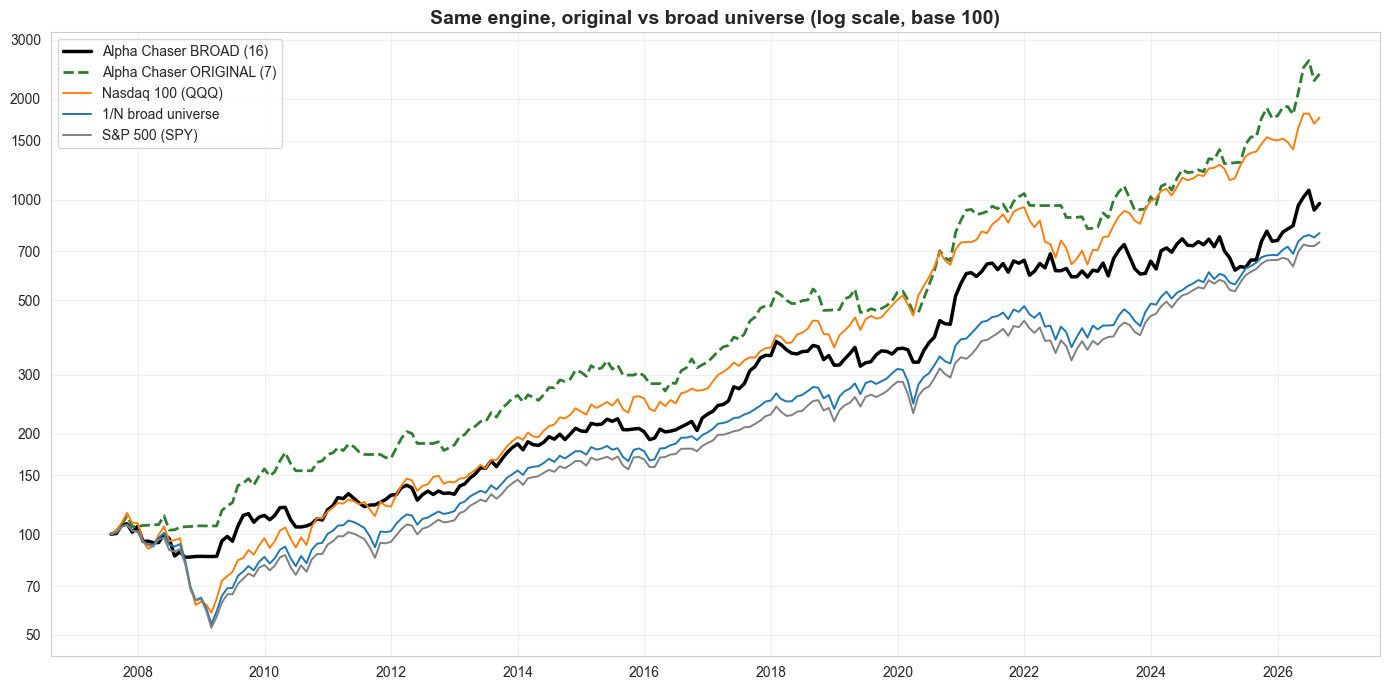

CAGR    original   18.06%  ->  broad   12.67%
Sharpe  original     0.92  ->  broad     0.69
MaxDD   original  -21.45%  ->  broad  -20.50%


In [9]:
if ff is not None:
    F_b = ff.reindex(S_b.index)
    bm.factor_regression(B_b["Alpha Chaser ORIGINAL (7)"], F_b[FF5 + ["UMD"]], RF_b, "FF5 + UMD, original universe")
    bm.factor_regression(S_b, F_b[FF5 + ["UMD"]], RF_b, "FF5 + UMD, broad universe")

held = w_b.loc[S_b.index[0]:]
freq = pd.DataFrame({"Months held": (held > 0).sum(), "Frequency %": ((held > 0).mean() * 100).round(1)})
freq = freq[freq["Months held"] > 0].sort_values("Months held", ascending=False)
freq["Added sector"] = ["yes" if t in EXTRA_SECTORS else "" for t in freq.index]
print("HOLDINGS FREQUENCY, BROAD UNIVERSE")
print(freq.to_string(), "\n")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 7))
for label, r, style in [(name_b, S_b, dict(color="black", lw=2.5)),
                        ("Alpha Chaser ORIGINAL (7)", B_b["Alpha Chaser ORIGINAL (7)"], dict(color="#2E7D32", lw=2, ls="--")),
                        ("Nasdaq 100 (QQQ)", B_b["Nasdaq 100 (QQQ)"], dict(color="#ff7f0e", lw=1.4)),
                        ("1/N broad universe", B_b["1/N broad universe"], dict(color="#1f77b4", lw=1.4)),
                        ("S&P 500 (SPY)", B_b["S&P 500 (SPY)"], dict(color="grey", lw=1.4))]:
    ax.plot(bm.equity_curve(r), label=label, **style)
bm._log_axis(ax)
ax.set_title("Same engine, original vs broad universe (log scale, base 100)", fontsize=14, fontweight="bold")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

st_o, st_b = bm.perf_stats(B_b["Alpha Chaser ORIGINAL (7)"], RF_b), bm.perf_stats(S_b, RF_b)
for k, f in [("CAGR", "{:.2%}"), ("Sharpe", "{:.2f}"), ("MaxDD", "{:.2%}")]:
    print(f"{k:<7} original {f.format(st_o[k]):>8}  ->  broad {f.format(st_b[k]):>8}")

### Reading the results

On the original universe the strategy shows a large and significant alpha, including after FF5 + momentum. On the broad universe CAGR falls by roughly a third and the alpha is no longer significant at 5%: a meaningful part of the original excess return comes from **universe selection**, not from the engine. What survives is a momentum-driven equity strategy with much smaller drawdowns than buy-and-hold. The concentrated version stays in paper trading as a forward test, not as evidence of skill.